# Fase 2: integración

Une en **una sola tabla** todo lo que sale de la limpieza: los sensores (`tables`),
los PIR (`pir`) y la etiqueta (`labels`). Como todo comparte la misma rejilla de
tiempo, cada fila será un instante (cada 10 s) con todas sus medidas y su nivel.

Este notebook no repite la limpieza: la toma ya hecha con la función `clean` de
`src/occupancy/cleaning.py`.

Diapositivas: clase 7, 24 (Data Integration) y 27–33 (redundancia y correlación).

In [2]:
import json
import sys
from pathlib import Path

import pandas as pd
import yaml

# Raíz del repositorio y acceso al código de src/
ROOT = Path.cwd()
while not (ROOT / "config.yaml").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from occupancy.cleaning import clean

with open(ROOT / "config.yaml", encoding="utf-8") as f:
    config = yaml.safe_load(f)

with open(ROOT / "data" / "simulated" / "readings.json", encoding="utf-8") as f:
    data = json.load(f)["data"]

# Fase 1 completa en una línea
tables, pir, labels = clean(data, config["cleaning"])

print("Sensores:", list(tables))
print("PIR:", list(pir.columns))
print("Etiqueta:", list(labels.columns))

Sensores: ['pressure', 'humidity', 'temperature', 'co2Equivalent', 'voc', 'iaq', 'mic_vol', 'wifiPackets', 'bleAdverts']
PIR: ['timestamp', 'pir-1', 'pir-2', 'pir-3']
Etiqueta: ['timestamp', 'busy_level']


## Tu tarea: unir todo en una tabla

Guarda el resultado en una tabla llamada **`df`**:

- **Índice:** `timestamp`.
- **Columnas:** una por sensor (con el nombre del sensor), `pir-1`, `pir-2`, `pir-3`
  y `busy_level`.

Pasos:

1. Convierte cada tabla de `tables` en una serie con `timestamp` como índice
   (`set_index`) y quédate con su columna `value`, guardándola con el nombre del sensor.
2. Haz lo mismo con `pir` y `labels`: `set_index("timestamp")` y ya tienen sus columnas.
3. Únelas todas por el índice con `pd.concat([...], axis=1)`.

`axis=1` significa "pegar al lado" (como columnas), alineando las filas por su índice.

In [4]:
# Tu código aquí
pf=None
parts = []
for sensor, table in tables.items():
    column = table.set_index("timestamp")["value"].rename(sensor)
    parts.append(column)

parts.append(pir.set_index("timestamp"))
parts.append(labels.set_index("timestamp"))

df = pd.concat(parts, axis=1)
print(df.head())

                     pressure  humidity  temperature  co2Equivalent       voc  \
timestamp                                                                       
2026-10-20 09:00:00   1012.70     44.99        21.01     462.900000  0.672000   
2026-10-20 09:00:10   1012.75     45.28        21.02     463.950000  0.638500   
2026-10-20 09:00:20   1012.70     45.36        21.05     469.200000  0.660667   
2026-10-20 09:00:30   1013.52     45.45        21.06     477.200000  0.628667   
2026-10-20 09:00:40   1012.85     45.63        21.08     487.633333  0.618333   

                       iaq   mic_vol  wifiPackets  bleAdverts  pir-1  pir-2  \
timestamp                                                                     
2026-10-20 09:00:00  179.5  0.291000         79.0        44.0  100.0   90.0   
2026-10-20 09:00:10  175.1  0.312000         85.0        46.0   90.0  100.0   
2026-10-20 09:00:20  172.0  0.317000         80.0        54.0  100.0  100.0   
2026-10-20 09:00:30  176.9  0.322667 

In [5]:
# Comprobación de la integración (no hace falta modificarla)
expected_columns = set(tables) | {"pir-1", "pir-2", "pir-3", "busy_level"}
checks = {
    "1080 filas": len(df) == 1080,
    "índice de fechas": isinstance(df.index, pd.DatetimeIndex),
    "columnas correctas": set(df.columns) == expected_columns,
    "sin horas repetidas": not df.index.duplicated().any(),
    "21 filas sin etiqueta": df["busy_level"].isna().sum() == 21,
}
for name, ok in checks.items():
    print(f"{name:22} {'OK' if ok else 'REVISAR'}")

1080 filas             OK
índice de fechas       OK
columnas correctas     OK
sin horas repetidas    OK
21 filas sin etiqueta  OK


## Mirar la tabla

Antes de seguir, conviene ver qué ha quedado. Prueba con:

- `df.head()`: las primeras filas.
- `df.describe()`: mínimo, máximo y media de cada columna.
- `df.isna().sum()`: cuántos vacíos tiene cada columna.
- `df["busy_level"].value_counts()`: cuántas filas hay de cada nivel.

In [6]:
# Tu código aquí
print(df.shape)
print(df.isna().sum())
print(df["busy_level"].value_counts().sort_index())
df.describe()

(1080, 13)
pressure         18
humidity         18
temperature      18
co2Equivalent    18
voc              18
iaq              18
mic_vol          18
wifiPackets      18
bleAdverts       18
pir-1            18
pir-2            18
pir-3            18
busy_level    21
dtype: int64
busy_level
0.0    610
1.0     66
2.0    143
3.0    240
Name: count, dtype: int64


,pressure,humidity,temperature,co2Equivalent,voc,iaq,mic_vol,wifiPackets,bleAdverts,pir-1,pir-2,pir-3,busy_level
count,1062.000000,1062.000000,1062.000000,1062.000000,1062.000000,1062.000000,1062.000000,1062.000000,1062.000000,1062.000000,1062.000000,1062.000000,1059.000000
mean,1012.995678,46.175871,21.269336,600.609981,0.421323,74.123117,0.132433,32.585687,16.700565,39.147834,39.307910,39.030132,1.012276
std,0.293952,1.156724,0.299914,141.047495,0.156314,62.019338,0.102696,31.245368,16.277584,46.149103,46.319958,46.045311,1.272376
min,1012.040000,44.060000,20.810000,405.366667,0.210667,2.000000,0.007000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1012.790000,45.220000,21.030000,497.258333,0.292083,23.300000,0.047000,7.000000,4.000000,0.000000,0.000000,0.000000,0.000000
50%,1013.000000,45.970000,21.220000,552.900000,0.330833,33.500000,0.070667,12.000000,7.000000,0.000000,0.000000,0.000000,0.000000
75%,1013.190000,46.925000,21.420000,693.550000,0.564750,129.200000,0.225583,62.750000,31.000000,90.000000,90.000000,90.000000,2.000000
max,1013.920000,49.130000,22.050000,929.100000,0.737333,189.900000,0.328333,111.000000,64.000000,100.000000,100.000000,100.000000,3.000000


## Redundancia: correlación entre columnas

La diapositiva 27 habla de atributos redundantes, y la 31 de cómo detectarlos con la
**correlación**. `df.corr()` calcula la correlación de cada pareja de columnas
(de −1 a 1). Dos sensores con correlación muy cercana a 1 dicen casi lo mismo.

**Aviso:** con los datos simulados todo saldrá muy correlacionado, porque todos los
sensores se generaron a partir del número de personas. Aquí solo practicas cómo se
hace; las conclusiones se sacan con datos reales (fase de reducción).

In [7]:
# Tu código aquí
correlation = df.drop(columns="busy_level").corr()
correlation.round(2)

,pressure,humidity,temperature,co2Equivalent,voc,iaq,mic_vol,wifiPackets,bleAdverts,pir-1,pir-2,pir-3
pressure,1.00,-0.02,-0.05,-0.03,0.00,0.00,0.00,0.01,-0.02,0.01,0.01,0.01
humidity,-0.02,1.00,0.75,0.91,0.60,0.60,0.62,0.59,0.57,0.57,0.58,0.56
temperature,-0.05,0.75,1.00,0.83,0.48,0.48,0.49,0.46,0.45,0.40,0.41,0.41
co2Equivalent,-0.03,0.91,0.83,1.00,0.66,0.65,0.67,0.64,0.62,0.60,0.60,0.60
voc,0.00,0.60,0.48,0.66,1.00,0.97,0.97,0.96,0.93,0.94,0.94,0.94
iaq,0.00,0.60,0.48,0.65,0.97,1.00,0.97,0.97,0.94,0.96,0.96,0.95
mic_vol,0.00,0.62,0.49,0.67,0.97,0.97,1.00,0.96,0.94,0.94,0.94,0.94
wifiPackets,0.01,0.59,0.46,0.64,0.96,0.97,0.96,1.00,0.93,0.94,0.94,0.94
bleAdverts,-0.02,0.57,0.45,0.62,0.93,0.94,0.94,0.93,1.00,0.91,0.91,0.91
pir-1,0.01,0.57,0.40,0.60,0.94,0.96,0.94,0.94,0.91,1.00,0.99,0.99


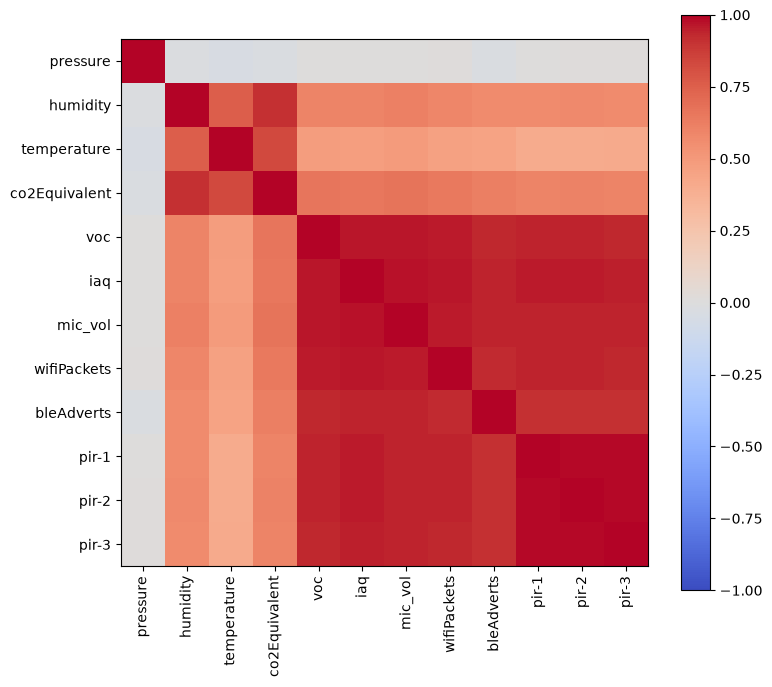

In [8]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 7))
image = ax.imshow(correlation, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(correlation)), correlation.columns, rotation=90)
ax.set_yticks(range(len(correlation)), correlation.columns)
fig.colorbar(image)
plt.tight_layout()
plt.show()